In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox, yeojohnson

In [ ]:
# 1. 화이트 와인
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 2. 레드 와인
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 3. 화이트 와인 + 레드 와인
white_wine['wine_type'] = 'white'
red_wine['wine_type'] = 'red'
all_wine = pd.concat([white_wine, red_wine], axis=0)

In [ ]:
def plot_dataset_with_stats(data, n_rows=5, n_cols=3):
    """
    데이터셋의 수치형 변수들과 'wine_type' 카테고리에 대해 히스토그램 및 카운트플롯을 그리고,
    주요 통계치(평균, 중앙값, 최대값, 최소값, 표준편차)를 표시합니다.

    :param data: pandas DataFrame, 시각화할 데이터셋
    :param n_rows: int, 그리드의 행 수
    :param n_cols: int, 그리드의 열 수
    """
    # 선택된 수치형 및 'wine_type' 열만 포함
    num_columns_log = data.select_dtypes(include=['float64', 'int64']).columns.tolist()
    if 'wine_type' in data.columns:
        num_columns_log.append('wine_type')  # 'wine_type' 열 추가

    # 서브플롯 생성
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*5))

    for r in range(n_rows):
        for c in range(n_cols):
            index = r * n_cols + c
            if index < len(num_columns_log):
                ax = axs[r][c]
                column = num_columns_log[index]

                if column == 'wine_type':
                    # 와인 종류에 대한 countplot
                    sns.countplot(x=data[column], ax=ax)
                else:
                    # 수치형 변수에 대한 histplot
                    sns.histplot(data[column], kde=True, ax=ax)


                    # 통계치 계산
                    mean_value = data[column].mean()
                    median_value = data[column].median()
                    max_value = data[column].max()
                    min_value = data[column].min()
                    std_value = data[column].std()

                    # 평균값을 나타내는 세로선 추가
                    ax.axvline(mean_value, color='r', linestyle='--')
                    ax.text(mean_value, ax.get_ylim()[1]*0.95, f'Mean: {mean_value:.2f}', color='r', ha='right')

                    # 통계치 표시
                    stats_text = f"Mean: {mean_value:.2f}\nMedian: {median_value:.2f}\nMax: {max_value}\nMin: {min_value}\nStd: {std_value:.2f}"
                    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top', horizontalalignment='right')

                ax.set_title(column)
            else:
                axs[r][c].axis('off')

    # 레이아웃 조정 및 그래프 표시
    plt.tight_layout()
    plt.show()

In [ ]:
def apply_selected_transformations(df):
    # 값이 0보다 큰 수치형 열만 선택
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns[df.min() > 0]
    transformed_dfs = {}

    # 로그 변환
    log_transformed_df = df.copy()
    for col in numeric_cols:
        log_transformed_df[col] = np.log(df[col])
    transformed_dfs['log'] = log_transformed_df

    # 제곱근 변환
    sqrt_transformed_df = df.copy()
    for col in numeric_cols:
        sqrt_transformed_df[col] = np.sqrt(df[col])
    transformed_dfs['sqrt'] = sqrt_transformed_df

    # 역수 변환
    reciprocal_transformed_df = df.copy()
    for col in numeric_cols:
        reciprocal_transformed_df[col] = 1 / df[col]
    transformed_dfs['reciprocal'] = reciprocal_transformed_df

    # 지수 변환
    exp_transformed_df = df.copy()
    for col in numeric_cols:
        # 지수 변환 전에 스케일링을 고려해야 합니다.
        scaled_col = df[col] / df[col].max()  # 스케일링
        exp_transformed_df[col] = np.exp(scaled_col)
    transformed_dfs['exp'] = exp_transformed_df

    return transformed_dfs

# 1. 화이트 와인

In [ ]:
#화이트 데이터셋 새로운 특성 추가
# total sulfur dioxide와 density의 상호작용
# total sulfur dioxide, density, residual sugar의 조합
# free sulfur dioxide와 total sulfur dioxide의 상호작용
# total sulfur dioxide와 density의 조합
# pH와 fixed acidity의 조합
# residual sugar와 total sulfur dioxide의 조합
# density와 alcohol의 조합

In [ ]:
#원본에 특성 추가
white_wine['interaction_sulfur_density'] = white_wine['total sulfur dioxide'] * white_wine['density']
white_wine['combined_sulfur_density_sugar'] = white_wine['total sulfur dioxide'] * white_wine['density'] * white_wine['residual sugar']
white_wine['interaction_free_total_sulfur'] = white_wine['free sulfur dioxide'] * white_wine['total sulfur dioxide']
white_wine['combined_sulfur_density'] = white_wine['total sulfur dioxide'] + white_wine['density']
white_wine['interaction_ph_acidity'] = white_wine['pH'] * white_wine['fixed acidity']
white_wine['combined_sugar_sulfur'] = white_wine['residual sugar'] + white_wine['total sulfur dioxide']
white_wine['combined_density_alcohol'] = white_wine['density'] * white_wine['alcohol']

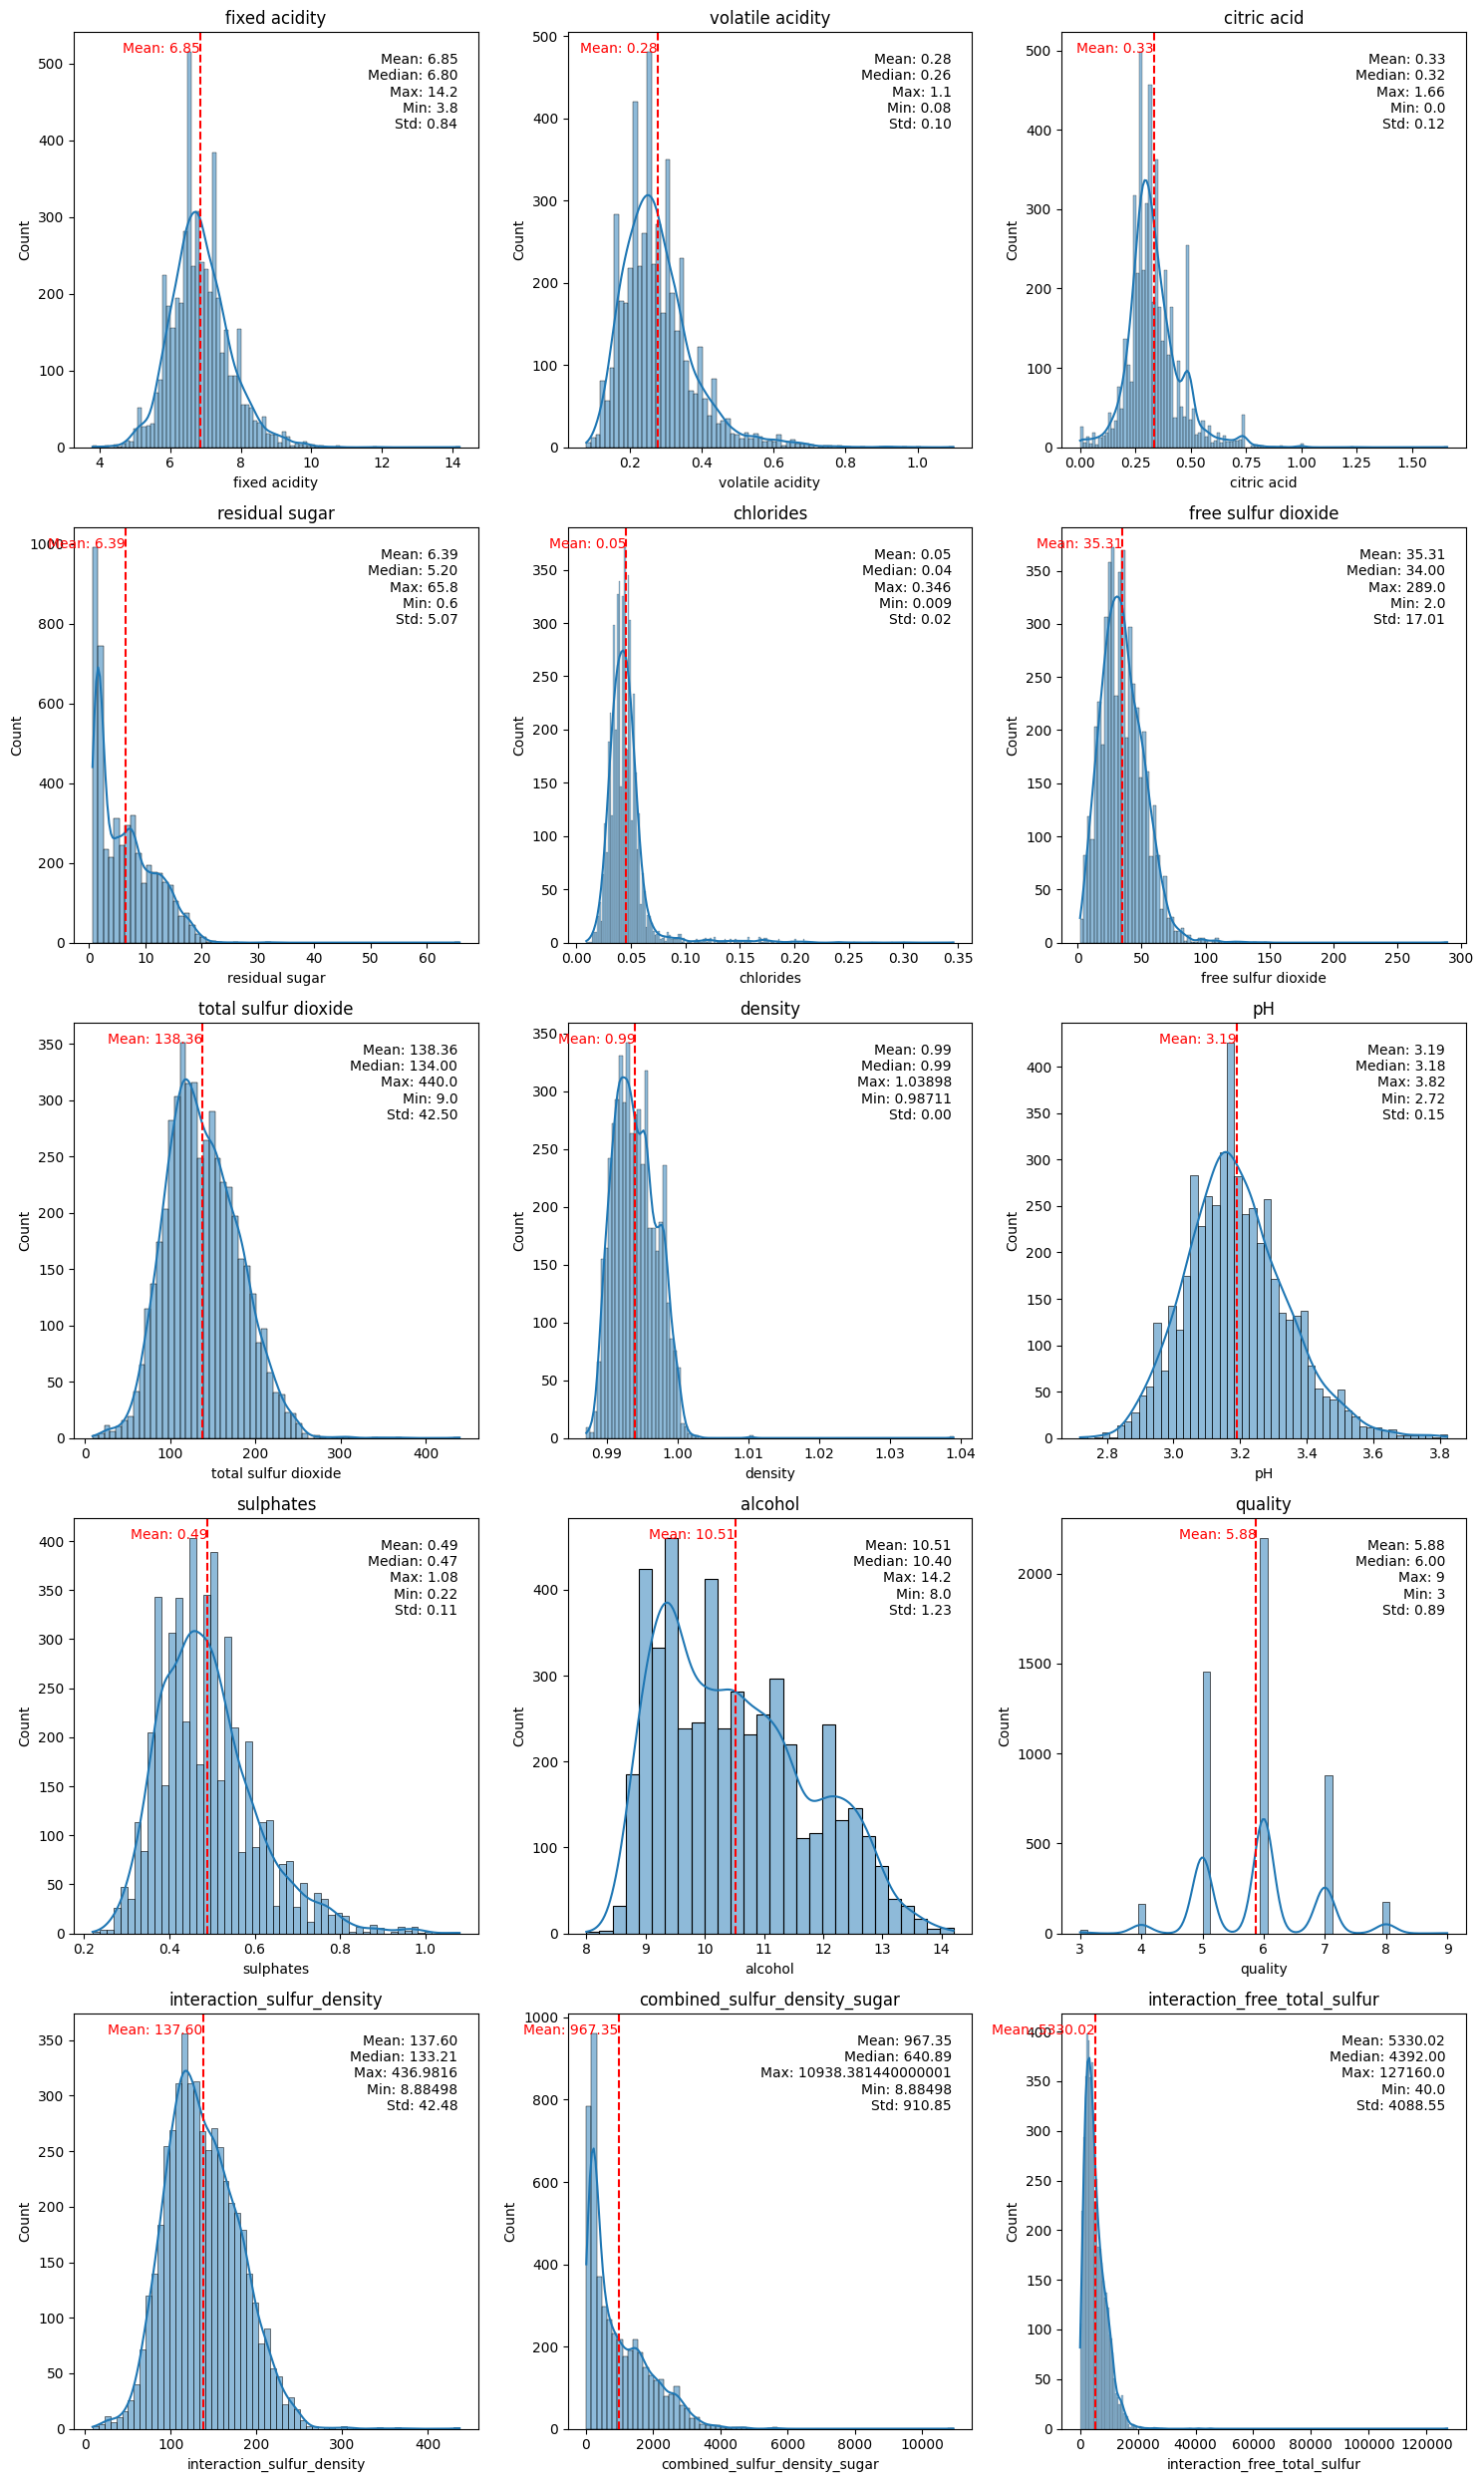

In [ ]:
#원본 화이트 와인
plot_dataset_with_stats(white_wine)

In [ ]:
# 변환 적용
transformed_dfs = apply_selected_transformations(white_wine)

# 각 변환된 데이터셋을 따로 저장
log_transformed_df = transformed_dfs['log']
sqrt_transformed_df = transformed_dfs['sqrt']
reciprocal_transformed_df = transformed_dfs['reciprocal']
# exp_transformed_df = transformed_dfs['exp']

TypeError: ignored

In [ ]:
#로그 변환 화이트 와인
plot_dataset_with_stats(log_transformed_df)

In [ ]:
#제곱근 변환 화이트 와인
plot_dataset_with_stats(sqrt_transformed_df)

In [ ]:
#역수 변환 화이트 와인
plot_dataset_with_stats(reciprocal_transformed_df)

In [ ]:
# white_wine
# log_transformed_df
# sqrt_transformed_df
# reciprocal_transformed_df

In [ ]:
# 특성 및 타겟 분리
X = white_wine.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = white_wine['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 원본")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = log_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = log_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 로그변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = sqrt_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = sqrt_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 제곱근변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = reciprocal_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = reciprocal_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 역수변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


# 레드 와인

In [ ]:
# density와 citric acid의 곱셈으로 fixed acidity와의 상호작용 특성 생성
# free sulfur dioxide와 total sulfur dioxide의 곱셈으로 상호작용 특성 생성
# pH와 fixed acidity 및 citric acid의 곱셈으로 복합 상호작용 특성 생성
# density와 alcohol의 곱셈으로 상호작용 특성 생성
# volatile acidity와 citric acid의 곱셈으로 상호작용 특성 생성

# red_wine
# log_transformed_df
# sqrt_transformed_df
# reciprocal_transformed_df

In [ ]:
red_wine['density_citric_acid_interaction'] = red_wine['density'] * red_wine['citric acid']
red_wine['free_total_sulfur_interaction'] = red_wine['free sulfur dioxide'] * red_wine['total sulfur dioxide']
red_wine['ph_fixed_citric_acid_interaction'] = red_wine['pH'] * red_wine['fixed acidity'] * red_wine['citric acid']
red_wine['density_alcohol_interaction'] = red_wine['density'] * red_wine['alcohol']
red_wine['volatile_citric_acid_interaction'] = red_wine['volatile acidity'] * red_wine['citric acid']

In [ ]:
#원본 레드 와인
plot_dataset_with_stats(red_wine)

In [ ]:
def apply_selected_transformations(df):
    # Select only numeric columns with all values greater than 0
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    positive_numeric_cols = [col for col in numeric_cols if (df[col] > 0).all()]

    transformed_dfs = {}

    # Log transformation
    log_transformed_df = df.copy()
    for col in positive_numeric_cols:
        log_transformed_df[col] = np.log(df[col])
    transformed_dfs['log'] = log_transformed_df

    # Square root transformation
    sqrt_transformed_df = df.copy()
    for col in positive_numeric_cols:
        sqrt_transformed_df[col] = np.sqrt(df[col])
    transformed_dfs['sqrt'] = sqrt_transformed_df

    # Reciprocal transformation
    reciprocal_transformed_df = df.copy()
    for col in positive_numeric_cols:
        reciprocal_transformed_df[col] = 1 / df[col]
    transformed_dfs['reciprocal'] = reciprocal_transformed_df

    # Exponential transformation
    exp_transformed_df = df.copy()
    for col in positive_numeric_cols:
        # Consider scaling before exponential transformation to prevent overflow
        scaled_col = df[col] / df[col].max()  # Scaling
        exp_transformed_df[col] = np.exp(scaled_col)
    transformed_dfs['exp'] = exp_transformed_df

    return transformed_dfs
# 변환 적용
transformed_dfs = apply_selected_transformations(red_wine)
# 각 변환된 데이터셋을 따로 저장
log_transformed_df = transformed_dfs['log']
sqrt_transformed_df = transformed_dfs['sqrt']
reciprocal_transformed_df = transformed_dfs['reciprocal']
# exp_transformed_df = transformed_dfs['exp']

In [ ]:
#로그 변환 레드 와인
plot_dataset_with_stats(log_transformed_df)

In [ ]:
#제곱근 변환 레드 와인
plot_dataset_with_stats(sqrt_transformed_df)

In [ ]:
#역수 변환 레드 와인
plot_dataset_with_stats(reciprocal_transformed_df)

In [ ]:
# 특성 및 타겟 분리
X = red_wine.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = red_wine['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("레드 원본")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = log_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = log_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("레드 로그 변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = sqrt_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = sqrt_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("레드 제곱근 변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = reciprocal_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = reciprocal_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("레드 역수 변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


# 화이트 + 레드 와인

In [ ]:
# fixed acidity와 residual sugar
# residual sugar와 free sulfur dioxide
# residual sugar와 density
# density와 total sulfur dioxide
# density와 alcohol

In [ ]:
all_wine

In [ ]:
all_wine.isnull().sum()

In [ ]:
all_wine['fixed_acidity_residual_sugar'] = all_wine['fixed acidity'] * all_wine['residual sugar']
all_wine['residual_sugar_free_sulfur_dioxide'] = all_wine['residual sugar'] * all_wine['free sulfur dioxide']
all_wine['residual_sugar_density'] = all_wine['residual sugar'] * all_wine['density']
all_wine['density_total_sulfur_dioxide'] = all_wine['density'] * all_wine['total sulfur dioxide']
all_wine['density_alcohol'] = all_wine['density'] * all_wine['alcohol']

In [ ]:
all_wine.isnull().sum()

In [ ]:
# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

all_wine = pd.concat([white_wine, red_wine_upsampled])

In [ ]:
all_wine.isnull().sum()

In [ ]:
#원본 화이트 + 레드 와인
plot_dataset_with_stats(all_wine)

In [ ]:
all_wine

In [ ]:
import statsmodels.api as sm
X = all_wine.drop('quality', axis=1)
X = X.drop('wine_type', axis=1)
y = all_wine['quality']
X = sm.add_constant(X)
model = sm.OLS(y,X)
results = model.fit()
print(results.params)
print(results.summary())

In [ ]:
def apply_selected_transformations(df):
    # Select only numeric columns with all values greater than 0
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    positive_numeric_cols = [col for col in numeric_cols if (df[col] > 0).all()]

    transformed_dfs = {}

    # Log transformation
    log_transformed_df = df.copy()
    for col in positive_numeric_cols:
        log_transformed_df[col] = np.log(df[col])
    transformed_dfs['log'] = log_transformed_df

    # Square root transformation
    sqrt_transformed_df = df.copy()
    for col in positive_numeric_cols:
        sqrt_transformed_df[col] = np.sqrt(df[col])
    transformed_dfs['sqrt'] = sqrt_transformed_df

    # Reciprocal transformation
    reciprocal_transformed_df = df.copy()
    for col in positive_numeric_cols:
        reciprocal_transformed_df[col] = 1 / df[col]
    transformed_dfs['reciprocal'] = reciprocal_transformed_df

    # Exponential transformation
    exp_transformed_df = df.copy()
    for col in positive_numeric_cols:
        # Consider scaling before exponential transformation to prevent overflow
        scaled_col = df[col] / df[col].max()  # Scaling
        exp_transformed_df[col] = np.exp(scaled_col)
    transformed_dfs['exp'] = exp_transformed_df

    return transformed_dfs
# 변환 적용
transformed_dfs = apply_selected_transformations(all_wine)

# 각 변환된 데이터셋을 따로 저장
log_transformed_df = transformed_dfs['log']
sqrt_transformed_df = transformed_dfs['sqrt']
reciprocal_transformed_df = transformed_dfs['reciprocal']
# exp_transformed_df = transformed_dfs['exp']

In [ ]:
#로그 변환 화이트 + 레드 와인
plot_dataset_with_stats(log_transformed_df)

In [ ]:
#제곱근 변환 화이트 + 레드 와인
plot_dataset_with_stats(sqrt_transformed_df)

In [ ]:
#역수 변환 화이트 + 레드 와인
plot_dataset_with_stats(reciprocal_transformed_df)

In [ ]:
# 특성 및 타겟 분리
X = all_wine.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = all_wine['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 원본")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = log_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = log_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 로그변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = sqrt_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = sqrt_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 제곱근변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()


In [ ]:
# 특성 및 타겟 분리
X = reciprocal_transformed_df.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = reciprocal_transformed_df['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 역수변환")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 모델별 성능 지표를 저장할 리스트
mse_scores = []
rmse_scores = []
r2_scores = []

# 이전에 정의된 모델 훈련 및 평가 코드는 생략하고, 직접 성능 지표를 계산하는 부분을 시작합니다.
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)
    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 성능 지표를 리스트에 추가
    mse_scores.append(mse)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # 결과 출력
    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

# 성능 지표 시각화
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# MSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[0].bar(model_names[i], mse_scores[i], color='skyblue')
    ax[0].text(i, mse_scores[i], f'{mse_scores[i]:.2f}', ha='center', va='bottom')

ax[0].set_title('MSE of Models')
ax[0].set_ylabel('MSE')
ax[0].set_xticklabels(model_names, rotation=45)

# RMSE 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[1].bar(model_names[i], rmse_scores[i], color='lightgreen')
    ax[1].text(i, rmse_scores[i], f'{rmse_scores[i]:.2f}', ha='center', va='bottom')

ax[1].set_title('RMSE of Models')
ax[1].set_ylabel('RMSE')
ax[1].set_xticklabels(model_names, rotation=45)

# R^2 바 차트와 레이블 추가
for i in range(len(model_names)):
    ax[2].bar(model_names[i], r2_scores[i], color='lightcoral')
    ax[2].text(i, r2_scores[i], f'{r2_scores[i]:.2f}', ha='center', va='bottom')

ax[2].set_title('R^2 of Models')
ax[2].set_ylabel('R^2')
ax[2].set_xticklabels(model_names, rotation=45)

# 레이아웃 조정
plt.tight_layout()
plt.show()
